In [3]:
import requests 
import pandas as pd

In [ ]:
CLIENT = "WebDataScience/1.0 (micah.crowe@colorado.edu)"
HEADERS = {"User-Agent": f"{CLIENT} python-requests/{requests.__version__}"}

In [5]:
cdx_url = "https://web.archive.org/cdx/search/cdx"

params = {
    "url": "https://www.reddit.com/dev/api",
    "output": "json",
    "fl": "timestamp,original,statuscode,length",
    "filter": "statuscode:200", 
    "collapse": "digest",        
}

response = requests.get(cdx_url, params=params)
data = response.json()

df = pd.DataFrame(data[1:], columns=data[0])
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y%m%d%H%M%S")
df["length"] = pd.to_numeric(df["length"], errors="coerce")

print(f"Total snapshots: {len(df)}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")

Total snapshots: 1245
Date range: 2012-03-27 00:43:36 to 2026-10-21 02:21:45


In [1]:
#import matplotlib.pyplot as plt

#fig, ax = plt.subplots(figsize=(12, 4))

#df.set_index("timestamp")["length"].plot(ax=ax)
#ax.set_ylabel("Page size (bytes)")
#ax.set_title("Page Size Over Time")

#plt.tight_layout()
#plt.show()

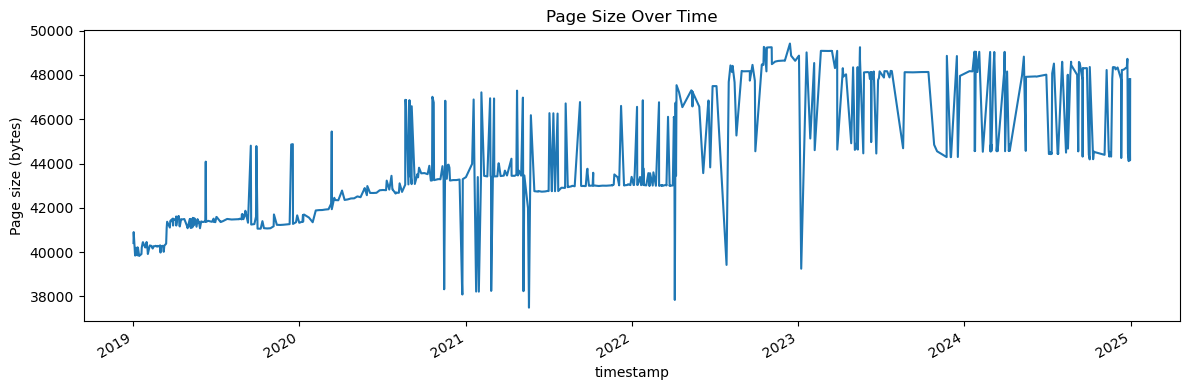

In [23]:
start = '2019-01-01'
end = '2025-01-01'

subset = df[(df["timestamp"] >= start) & (df["timestamp"] <= end)]

fig, ax = plt.subplots(figsize=(12, 4))

subset.set_index("timestamp")["length"].plot(ax=ax)
ax.set_ylabel("Page size (bytes)")
ax.set_title("Page Size Over Time")

plt.tight_layout()
plt.show()

In [33]:
def page_length_graph(url):
    
    cdx_url = "https://web.archive.org/cdx/search/cdx"

    params = {
        
    "url": url,
    "output": "json",
    "fl": "timestamp,original,statuscode,length",
    "filter": "statuscode:200", 
    "collapse": "digest",        
    }

    resp = requests.get(cdx_url, params)
    data = resp.json()
    
    df = pd.DataFrame(data[1:], columns=data[0])
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y%m%d%H%M%S")
    df["length"] = pd.to_numeric(df["length"], errors="coerce")

    fig, ax = plt.subplots(figsize=(12, 4))

    df.set_index("timestamp")["length"].plot(ax=ax)
    ax.set_ylabel("Page size (bytes)")
    ax.set_title("Page Size Over Time")

    plt.tight_layout()
    plt.show()   

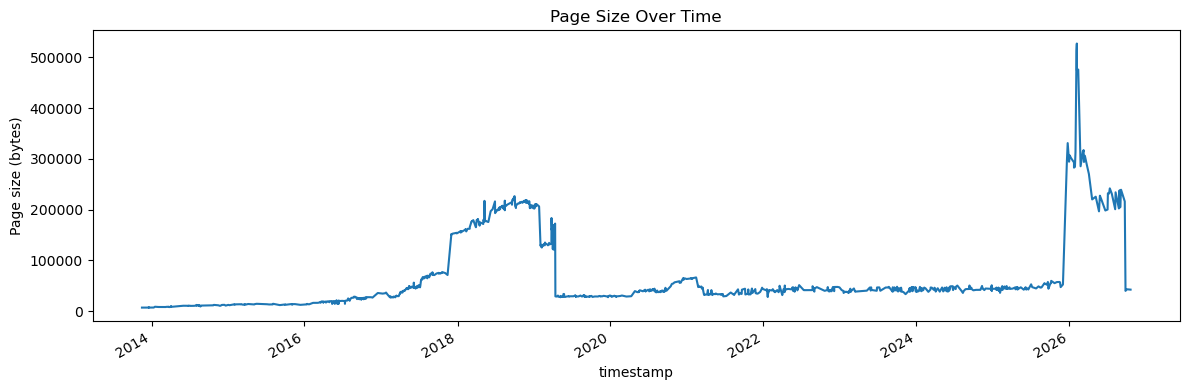

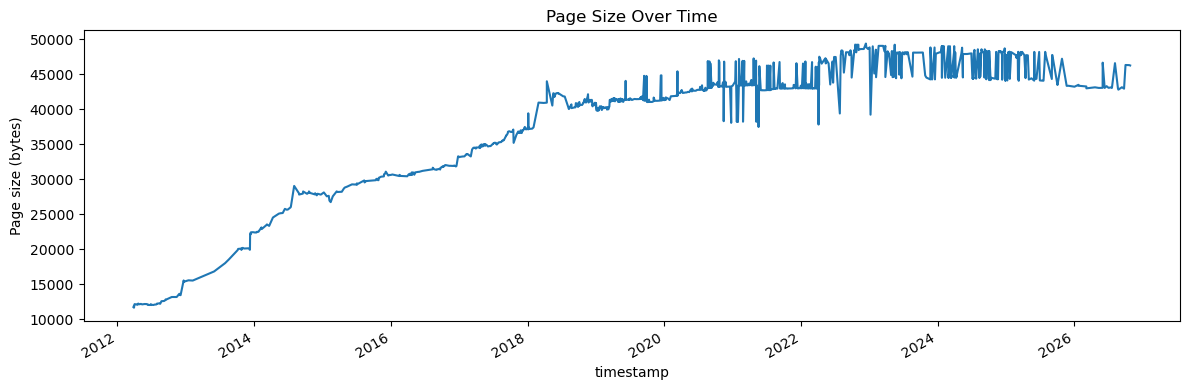

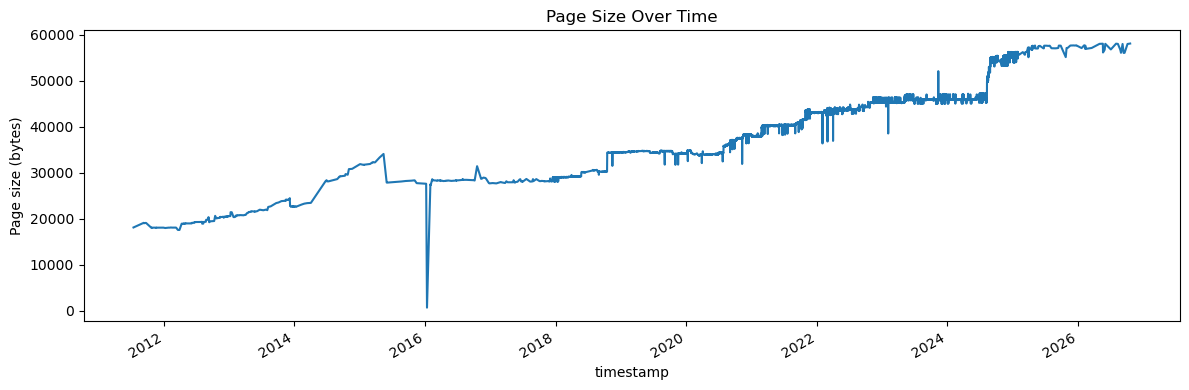

In [45]:
urls = [
    'https://developers.facebook.com/docs/graph-api/', # facebook
    'https://www.reddit.com/dev/api', # reddit
    'https://www.tumblr.com/docs/en/api/v2', # tumblr
]

for url in urls:
    page_length_graph(url)

In [ ]:
# Heatmap api enpoint availibility 